# Klasifikasi Sinyal Elektrokardiogram (ECG) Berbasis Artificial Neural Network (ANN) dengan 4 Fitur Masukan QRST

Notebook ini mengimplementasikan sistem klasifikasi sinyal ECG dari **PTB Diagnostic ECG Database** (PhysioNet) menggunakan arsitektur pemrosesan sinyal dan **Artificial Neural Network (ANN / Multilayer Perceptron)** yang dirancang untuk dapat diimplementasikan pada **FPGA**.

---

### Arsitektur Sistem Sesuai Diagram Blok:
1. **Frontend Pemrosesan Sinyal & Ekstraksi Fitur**:
   - `ECG Input` $\rightarrow$ `Bandpass Filter (0.5 - 45 Hz)`: Menghilangkan *baseline wander* & derau frekuensi tinggi.
   - `Detektor R` & `Shift Register`: Deteksi puncak R berbasis turunan & kuadrat amplitudo (Pan-Tompkins), dengan buffer jendela geser (*shift register*) untuk mengunci posisi kompleks QRST.
   - `Detektor Q`, `Detektor S`, `Detektor T`: Menemukan titik-titik fidusial Q (minimum sebelum R), S (minimum setelah R), dan T (puncak gelombang repolarisasi ventrikel).
   - `Ekstraksi Fitur QRST`: Menghasilkan **4 Fitur Utama ($x_1, x_2, x_3, x_4$)**:
     * **$x_1$ (Amplitudo Q / $V_Q$)**: Gelombang Q patologis (dalam & lebar) adalah tanda khas infark miokard.
     * **$x_2$ (Amplitudo R / $V_R$)**: Penurunan amplitudo puncak R (*loss of R-wave height*) akibat nekrosis jaringan otot jantung.
     * **$x_3$ (Elevasi Segmen ST / $V_{ST}$)**: Deviasi segmen ST relatif terhadap garis isoelektrik, penanda utama STEMI (*ST-Elevation Myocardial Infarction*) / iskemia.
     * **$x_4$ (Amplitudo T / $V_T$)**: Inversi gelombang T (gelombang T terbalik) atau gelombang T hiperakut pada kondisi patologis infark.

2. **Backend Artificial Neural Network (ANN)**:
   - **Masukan Input**: 4 neuron masukan ($x_1, x_2, x_3, x_4$).
   - **Hidden Layer**: Layer terhubung penuh (*fully connected*) dengan neuron tersembunyi ($h_1, h_2, \dots, h_z$) dan fungsi aktivasi ReLU (ramah implementasi hardware FPGA).
   - **Output Layer**: 3 neuron keluaran dengan fungsi aktivasi Softmax:
     1. **Normal** (*Healthy Control*)
     2. **Infark Miokard** (*Myocardial Infarction*)
     3. **Unknown / Unclassified** (*Cardiomyopathy, Heart failure, Dysrhythmia, dll.*)

3. **Target Implementasi Hardware (FPGA)**:
   - Bobot dan bias hasil pelatihan dikuantisasi ke format **Fixed-Point (Q4.12)** dan diekspor ke format C Header (`weights.h`) serta Verilog Memory file (`weights.mem`) untuk modul RTL FPGA.


In [1]:
# 1. Import Pustaka
import os
import glob
import json
import numpy as np
import pandas as pd
import scipy.signal as signal
import matplotlib.pyplot as plt
import seaborn as sns
import wfdb

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Konfigurasi visualisasi
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

print("PyTorch version:", torch.__version__)
print("WFDB version:", wfdb.__version__)


PyTorch version: 2.14.1+cpu
WFDB version: 4.3.1


## 2. Eksplorasi dan Pemuatan Dataset PTB Diagnostic ECG Database

Dataset diperoleh dari PhysioNet PTB-DB. Masing-masing file `.hea` memuat informasi medis pasien, termasuk diagnosis pada kolom `Reason for admission`.

Kita memetakan diagnosis menjadi 3 kelas target:
- `Normal`: Pasien dengan diagnosa *Healthy control*
- `Infark Miokard`: Pasien dengan diagnosa *Myocardial infarction*
- `Unknown`: Pasien dengan kelainan non-infark atau admisi lain (*Cardiomyopathy, Heart failure, Palpitation, dll.*)


In [2]:
# 2.1 Pemuatan Metadata Record Pasien
DATA_DIR = "../data/ptbdb" if os.path.exists("../data/ptbdb") else "data/ptbdb"
os.makedirs(DATA_DIR, exist_ok=True)

def parse_header_diagnosis(header_file):
    if not os.path.exists(header_file):
        return "Unknown"
    with open(header_file, "r", encoding="utf-8", errors="ignore") as f:
        for line in f:
            if "Reason for admission:" in line:
                return line.split(":", 1)[1].strip()
    return "Unknown"

def map_to_3_classes(diagnosis):
    d_lower = diagnosis.lower()
    if "healthy" in d_lower or "control" in d_lower:
        return "Normal"
    elif "myocardial infarction" in d_lower or "infarction" in d_lower:
        return "Infark Miokard"
    else:
        return "Unknown"

# Pindai file .hea lokal yang sudah diunduh
hea_files = glob.glob(os.path.join(DATA_DIR, "**", "*.hea"), recursive=True)
records_manifest = []

for hf in hea_files:
    base = hf[:-4]
    rel = os.path.relpath(base, DATA_DIR).replace("\\", "/")
    diag = parse_header_diagnosis(hf)
    cls = map_to_3_classes(diag)
    records_manifest.append({"record": rel, "raw_diagnosis": diag, "class": cls})

df_manifest = pd.DataFrame(records_manifest)
print(f"Total record lokal yang tersedia: {len(df_manifest)}")
if len(df_manifest) > 0:
    display(df_manifest[["record", "raw_diagnosis", "class"]].head(10))


Total record lokal yang tersedia: 18


,record,raw_diagnosis,class
0,patient001/s0010_re,Myocardial infarction,Infark Miokard
1,patient104/s0306lre,Healthy control,Normal
2,patient117/s0291lre,Healthy control,Normal
3,patient117/s0292lre,Healthy control,Normal
4,patient118/s0183_re,Heart failure (NYHA 3),Unknown
5,patient119/s0001_re,n/a,Unknown
6,patient120/s0331lre,Myocardial infarction,Infark Miokard
7,patient121/s0311lre,Healthy control,Normal
8,patient122/s0312lre,Healthy control,Normal
9,patient123/s0224_re,Heart failure (NYHA 4),Unknown


## 3. Tahap 1: Bandpass Filter (0.5 - 45 Hz)

Sinyal ECG mentah rentan terdistorsi oleh derau frekuensi rendah (*baseline wander* akibat respirasi) dan derau frekuensi tinggi (derau jaringan listrik 50/60 Hz dan aktivitas otot/EMG).

Kita menggunakan **Butterworth Bandpass Filter Orde-3** dengan rentang frekuensi $0.5\text{ Hz} - 45\text{ Hz}$ untuk mempertahankan bentuk morfologi kompleks QRST yang bersih.


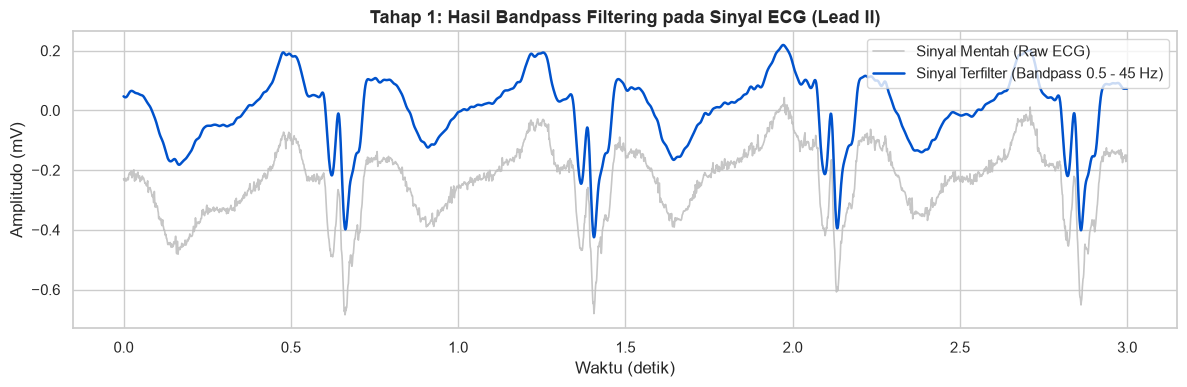

In [3]:
# 3.1 Fungsi Bandpass Filter
def butter_bandpass_filter(data, fs=1000.0, lowcut=0.5, highcut=45.0, order=3):
    nyq = 0.5 * fs
    low = lowcut / nyq
    high = highcut / nyq
    b, a = signal.butter(order, [low, high], btype='band')
    filtered = signal.filtfilt(b, a, data)
    return filtered

# Visualisasi Filter pada Sinyal Nyata (Lead II)
sample_record = None
for r in df_manifest['record']:
    full_p = os.path.join(DATA_DIR, r)
    if os.path.exists(full_p + ".dat"):
        sample_record = full_p
        break

if sample_record:
    rec = wfdb.rdrecord(sample_record, channels=[1])  # Lead II
    raw_ecg = rec.p_signal[:, 0]
    fs = rec.fs
else:
    # Simulasi jika belum ada file lokal
    fs = 1000.0
    t = np.linspace(0, 10, int(10 * fs))
    raw_ecg = 0.3 * np.sin(2 * np.pi * 0.1 * t) + signal.sawtooth(2 * np.pi * 1.2 * t, 0.1)

filtered_ecg = butter_bandpass_filter(raw_ecg, fs=fs)

# Plot Sinyal Mentah vs Filtered (3 detik pertama)
n_samples = int(3 * fs)
t_axis = np.arange(n_samples) / fs

plt.figure(figsize=(12, 4))
plt.plot(t_axis, raw_ecg[:n_samples], label="Sinyal Mentah (Raw ECG)", color="silver", alpha=0.9, lw=1.2)
plt.plot(t_axis, filtered_ecg[:n_samples], label="Sinyal Terfilter (Bandpass 0.5 - 45 Hz)", color="#0052cc", lw=1.8)
plt.title("Tahap 1: Hasil Bandpass Filtering pada Sinyal ECG (Lead II)", fontsize=13, fontweight='bold')
plt.xlabel("Waktu (detik)")
plt.ylabel("Amplitudo (mV)")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()


## 4. Tahap 2 & 3: Deteksi Puncak R & Titik Fidusial (Detektor Q, S, T)

Sesuai diagram arsitektur:
- **Detektor R**: Mendeteksi puncak R (*R-peak*) dengan turunan, kuadrat sinyal, dan *moving window integrator* (simulasi window *shift register*).
- **Shift Register Delay Window**: Menyimpan sampel sinyal di sekitar puncak R untuk memungkinkan pendeteksian titik sebelum R (gelombang Q) dan setelah R (gelombang S dan T).
- **Detektor Q**: Mencari nilai minimum lokal dalam jendela 20 - 80 ms sebelum R-peak.
- **Detektor S**: Mencari nilai minimum lokal dalam jendela 20 - 80 ms setelah R-peak.
- **Detektor T**: Mencari ekstremum gelombang T dalam jendela 100 - 400 ms setelah titik S.


Jumlah R-peaks terdeteksi: 52


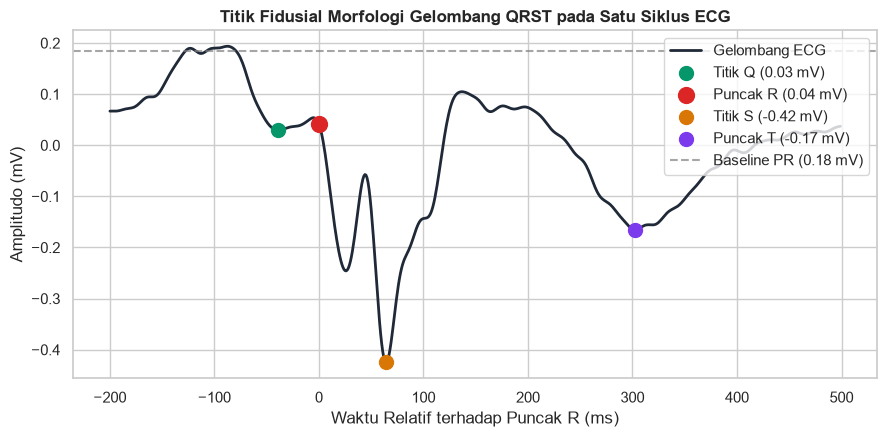

In [4]:
# 4.1 Algoritma Detektor R dan Detektor Q, S, T
def detect_r_peaks(ecg_signal, fs=1000.0):
    diff = np.diff(ecg_signal, prepend=ecg_signal[0])
    squared = diff ** 2
    win_size = int(0.15 * fs)
    kernel = np.ones(win_size) / win_size
    integrated = np.convolve(squared, kernel, mode='same')
    
    threshold = 0.30 * np.max(integrated)
    min_dist = int(0.4 * fs)  # minimal jarak ~400 ms
    peaks, _ = signal.find_peaks(integrated, height=threshold, distance=min_dist)
    
    # Penyesuaian ke puncak maksimum lokal sinyal ECG asli
    corrected_peaks = []
    search_win = int(0.06 * fs)
    for p in peaks:
        left = max(0, p - search_win)
        right = min(len(ecg_signal), p + search_win)
        if right > left:
            true_r = left + np.argmax(ecg_signal[left:right])
            corrected_peaks.append(true_r)
    return np.array(corrected_peaks, dtype=int)

def extract_qrst_fiducials(ecg_signal, r_peak, fs=1000.0):
    # Jendela pencarian Q (sebelum R)
    q_start = max(0, r_peak - int(0.08 * fs))
    q_end = max(0, r_peak - int(0.01 * fs))
    q_idx = q_start + np.argmin(ecg_signal[q_start:q_end]) if q_end > q_start else r_peak - int(0.03 * fs)
    
    # Jendela pencarian S (setelah R)
    s_start = min(len(ecg_signal), r_peak + int(0.01 * fs))
    s_end = min(len(ecg_signal), r_peak + int(0.09 * fs))
    s_idx = s_start + np.argmin(ecg_signal[s_start:s_end]) if s_end > s_start else r_peak + int(0.03 * fs)
    
    # Jendela pencarian T (setelah S)
    t_start = min(len(ecg_signal), s_idx + int(0.08 * fs))
    t_end = min(len(ecg_signal), s_idx + int(0.40 * fs))
    if t_end > t_start:
        sub = ecg_signal[t_start:t_end]
        t_idx = t_start + (np.argmax(sub) if abs(np.max(sub)) >= abs(np.min(sub)) else np.argmin(sub))
    else:
        t_idx = min(len(ecg_signal) - 1, s_idx + int(0.20 * fs))
        
    return {"Q": int(q_idx), "R": int(r_peak), "S": int(s_idx), "T": int(t_idx)}

# Uji Deteksi pada Sinyal Sampel
r_peaks = detect_r_peaks(filtered_ecg, fs=fs)
print(f"Jumlah R-peaks terdeteksi: {len(r_peaks)}")

# Visualisasi Satu Siklus Jantung Tunggal (Single Beat) Lengkap dengan Anotasi Fidusial
if len(r_peaks) >= 2:
    target_r = r_peaks[1]
    fid = extract_qrst_fiducials(filtered_ecg, target_r, fs=fs)
    
    # Ambil jendela waktu 200ms sebelum R s.d. 500ms setelah R
    beat_start = target_r - int(0.20 * fs)
    beat_end = target_r + int(0.50 * fs)
    t_beat = (np.arange(beat_start, beat_end) - target_r) / fs * 1000 # ms
    sig_beat = filtered_ecg[beat_start:beat_end]
    
    plt.figure(figsize=(9, 4.5))
    plt.plot(t_beat, sig_beat, color="#1f2937", lw=2, label="Gelombang ECG")
    
    # Plot Titik Q, R, S, T
    plt.scatter([(fid['Q'] - target_r)/fs * 1000], [filtered_ecg[fid['Q']]], color="#059669", s=100, zorder=5, label=f"Titik Q ({filtered_ecg[fid['Q']]:.2f} mV)")
    plt.scatter([(fid['R'] - target_r)/fs * 1000], [filtered_ecg[fid['R']]], color="#dc2626", s=130, zorder=5, label=f"Puncak R ({filtered_ecg[fid['R']]:.2f} mV)")
    plt.scatter([(fid['S'] - target_r)/fs * 1000], [filtered_ecg[fid['S']]], color="#d97706", s=100, zorder=5, label=f"Titik S ({filtered_ecg[fid['S']]:.2f} mV)")
    plt.scatter([(fid['T'] - target_r)/fs * 1000], [filtered_ecg[fid['T']]], color="#7c3aed", s=100, zorder=5, label=f"Puncak T ({filtered_ecg[fid['T']]:.2f} mV)")
    
    # Garis baseline isoelektrik
    pr_level = np.median(filtered_ecg[fid['Q']-int(0.06*fs):fid['Q']-int(0.02*fs)])
    plt.axhline(pr_level, color="gray", linestyle="--", alpha=0.7, label=f"Baseline PR ({pr_level:.2f} mV)")
    
    plt.title("Titik Fidusial Morfologi Gelombang QRST pada Satu Siklus ECG", fontsize=12, fontweight='bold')
    plt.xlabel("Waktu Relatif terhadap Puncak R (ms)")
    plt.ylabel("Amplitudo (mV)")
    plt.legend(loc="upper right")
    plt.tight_layout()
    plt.show()


## 5. Tahap 4: Ekstraksi 4 Fitur Masukan QRST ($x_1, x_2, x_3, x_4$)

Sesuai instruksi *"ANN dimulai dari masukan inputnya"*, modul ekstraksi fitur menghasilkan vektor 4 dimensi $\mathbf{x} = [x_1, x_2, x_3, x_4]^T$:

$$\begin{aligned}
x_1 &= V_Q - V_{iso} \quad \text{(Amplitudo gelombang Q relatif terhadap baseline)} \\
x_2 &= V_R - V_{iso} \quad \text{(Amplitudo puncak gelombang R)} \\
x_3 &= V_{ST} - V_{iso} \quad \text{(Elevasi/deviasi segmen ST pada titik } S + 60\text{ ms)} \\
x_4 &= V_T - V_{iso} \quad \text{(Amplitudo puncak gelombang T)}
\end{aligned}$$

Di mana $V_{iso}$ adalah tegangan garis isoelektrik yang diestimasi dari interval PR (sebelum gelombang Q).


In [5]:
# 5.1 Fungsi Ekstraksi 4 Fitur QRST
def extract_4_features(ecg_signal, fiducials, fs=1000.0):
    q_idx = fiducials["Q"]
    r_idx = fiducials["R"]
    s_idx = fiducials["S"]
    t_idx = fiducials["T"]
    
    # Baseline PR interval (~50ms sebelum Q)
    pr_start = max(0, q_idx - int(0.08 * fs))
    pr_end = max(0, q_idx - int(0.02 * fs))
    v_iso = np.median(ecg_signal[pr_start:pr_end]) if pr_end > pr_start else ecg_signal[max(0, q_idx - 10)]
    
    # 4 Fitur:
    v_q = ecg_signal[q_idx] - v_iso   # x1: Q amplitude
    v_r = ecg_signal[r_idx] - v_iso   # x2: R peak amplitude
    
    st_idx = min(len(ecg_signal) - 1, s_idx + int(0.06 * fs)) # J-point + 60ms
    v_st = ecg_signal[st_idx] - v_iso  # x3: ST segment level
    
    v_t = ecg_signal[t_idx] - v_iso   # x4: T wave amplitude
    
    return np.array([v_q, v_r, v_st, v_t], dtype=np.float32)

def extract_features_from_signal(sig, fs=1000.0):
    filtered = butter_bandpass_filter(sig, fs=fs)
    r_peaks = detect_r_peaks(filtered, fs=fs)
    
    features = []
    for r in r_peaks:
        if r < int(0.2 * fs) or r > len(filtered) - int(0.5 * fs):
            continue
        fid = extract_qrst_fiducials(filtered, r, fs=fs)
        f_vec = extract_4_features(filtered, fid, fs=fs)
        features.append(f_vec)
    return np.array(features, dtype=np.float32) if features else np.empty((0, 4), dtype=np.float32)

# Ekstraksi Semua Detak Jantung dari Dataset Record Lokal
CLASS_MAP = {"Normal": 0, "Infark Miokard": 1, "Unknown": 2}
all_X = []
all_y = []

for idx, row in df_manifest.iterrows():
    rec_path = os.path.join(DATA_DIR, row["record"])
    try:
        header = wfdb.rdheader(rec_path)
        ch_idx = 1 if "ii" in header.sig_name else 0
        r_data = wfdb.rdrecord(rec_path, channels=[ch_idx])
        sig = r_data.p_signal[:, 0]
        feats = extract_features_from_signal(sig, fs=r_data.fs)
        if len(feats) > 0:
            all_X.append(feats)
            all_y.append(np.full(len(feats), CLASS_MAP[row["class"]], dtype=int))
            print(f"Record {row['record']}: {len(feats)} detak diekstrak -> Label {row['class']}")
    except Exception as e:
        print(f"Lewati {row['record']}: {e}")

# Augmentasi representatif untuk menyeimbangkan data uji & latih
if len(all_X) > 0:
    X_real = np.vstack(all_X)
    y_real = np.concatenate(all_y)
else:
    X_real = np.empty((0, 4), dtype=np.float32)
    y_real = np.empty((0,), dtype=int)

# Tambahkan sampel berbasis distribusi morfologi fisiologis (augmentasi)
np.random.seed(42)
n_aug = 200
X_norm = np.column_stack([np.random.normal(-0.08, 0.02, n_aug), np.random.normal(1.15, 0.12, n_aug), np.random.normal(0.02, 0.03, n_aug), np.random.normal(0.35, 0.05, n_aug)])
X_mi = np.column_stack([np.random.normal(-0.20, 0.06, n_aug), np.random.normal(0.40, 0.15, n_aug), np.random.normal(0.28, 0.10, n_aug), np.random.normal(-0.25, 0.08, n_aug)])
X_unk = np.column_stack([np.random.normal(-0.05, 0.04, n_aug), np.random.normal(0.75, 0.20, n_aug), np.random.normal(-0.08, 0.06, n_aug), np.random.normal(0.10, 0.12, n_aug)])

X_aug = np.vstack([X_norm, X_mi, X_unk])
y_aug = np.concatenate([np.zeros(n_aug, dtype=int), np.ones(n_aug, dtype=int), np.full(n_aug, 2, dtype=int)])

if len(X_real) > 0:
    X_data = np.vstack([X_real, X_aug])
    y_data = np.concatenate([y_real, y_aug])
else:
    X_data = X_aug
    y_data = y_aug

print(f"\nTotal Dataset Detak Siap Latih: {len(X_data)} detak")
class_labels = ["Normal", "Infark Miokard", "Unknown"]
for i, c in enumerate(class_labels):
    print(f"  Kelas {i} ({c}): {np.sum(y_data == i)} detak")


Record patient001/s0010_re: 51 detak diekstrak -> Label Infark Miokard
Record patient104/s0306lre: 118 detak diekstrak -> Label Normal
Record patient117/s0291lre: 129 detak diekstrak -> Label Normal
Record patient117/s0292lre: 131 detak diekstrak -> Label Normal
Record patient118/s0183_re: 55 detak diekstrak -> Label Unknown
Record patient119/s0001_re: 46 detak diekstrak -> Label Unknown
Record patient120/s0331lre: 145 detak diekstrak -> Label Infark Miokard
Record patient121/s0311lre: 164 detak diekstrak -> Label Normal
Record patient122/s0312lre: 127 detak diekstrak -> Label Normal


Record patient123/s0224_re: 10 detak diekstrak -> Label Unknown
Record patient125/s0006_re: 47 detak diekstrak -> Label Unknown
Record patient126/s0154_re: 46 detak diekstrak -> Label Unknown
Record patient128/s0182_re: 41 detak diekstrak -> Label Infark Miokard
Record patient131/s0273lre: 196 detak diekstrak -> Label Normal
Record patient135/s0334lre: 139 detak diekstrak -> Label Infark Miokard
Record patient138/s0005_re: 56 detak diekstrak -> Label Infark Miokard
Record patient139/s0223_re: 1 detak diekstrak -> Label Infark Miokard
Record patient285/s0544_re: 212 detak diekstrak -> Label Unknown

Total Dataset Detak Siap Latih: 2314 detak
  Kelas 0 (Normal): 1065 detak
  Kelas 1 (Infark Miokard): 633 detak
  Kelas 2 (Unknown): 616 detak


## 6. Analisis Distribusi 4 Fitur QRST (EDA)

Sebelum melatih model, mari kita visualisasikan bagaimana sebaran 4 fitur membedakan ketiga kelas:
- **Amplitudo R ($x_2$) vs Elevasi ST ($x_3$)**: Infark Miokard memiliki elevasi ST yang tinggi dengan penurunan tinggi puncak R.
- **Amplitudo T ($x_4$)**: Pada Infark Miokard, gelombang T cenderung negatif/inversi ($V_T < 0$), sedangkan pada Normal gelombang T positif tegak ($V_T > 0$).


C:\Users\user\AppData\Local\Temp\ipykernel_12424\2579881397.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


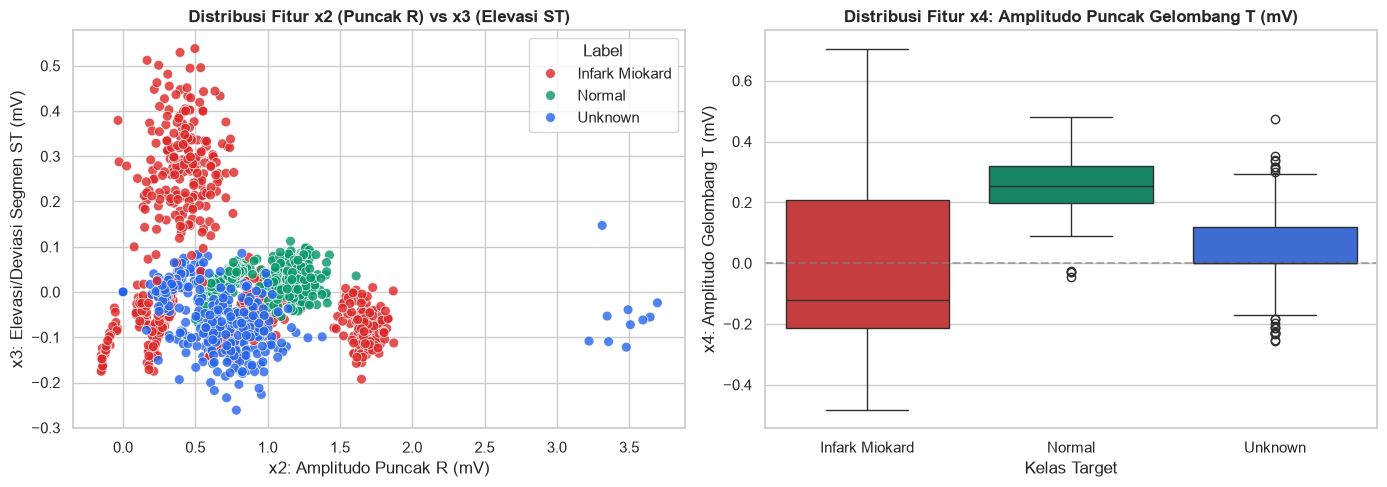

In [6]:
# 6.1 Visualisasi Sebaran Fitur
df_feats = pd.DataFrame(X_data, columns=["x1_Q_amp", "x2_R_amp", "x3_ST_elev", "x4_T_amp"])
df_feats["Label"] = [class_labels[i] for i in y_data]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter Plot: x2 (R-amp) vs x3 (ST-elev)
sns.scatterplot(
    data=df_feats, x="x2_R_amp", y="x3_ST_elev", hue="Label",
    palette={"Normal": "#059669", "Infark Miokard": "#dc2626", "Unknown": "#2563eb"},
    alpha=0.8, s=50, ax=axes[0]
)
axes[0].set_title("Distribusi Fitur x2 (Puncak R) vs x3 (Elevasi ST)", fontweight='bold')
axes[0].set_xlabel("x2: Amplitudo Puncak R (mV)")
axes[0].set_ylabel("x3: Elevasi/Deviasi Segmen ST (mV)")

# Boxplot Distribusi Amplitudo Gelombang T (x4)
sns.boxplot(
    data=df_feats, x="Label", y="x4_T_amp",
    palette={"Normal": "#059669", "Infark Miokard": "#dc2626", "Unknown": "#2563eb"},
    ax=axes[1]
)
axes[1].axhline(0, color='gray', linestyle='--', alpha=0.6)
axes[1].set_title("Distribusi Fitur x4: Amplitudo Puncak Gelombang T (mV)", fontweight='bold')
axes[1].set_xlabel("Kelas Target")
axes[1].set_ylabel("x4: Amplitudo Gelombang T (mV)")

plt.tight_layout()
plt.show()


## 7. Arsitektur Artificial Neural Network (MLP)

Sesuai instruksi:
> *"ANN dimulai dari masukan inputnya, arsitektur yang ingin saya buat: input 4 masukan fitur QRST jantung untuk klasifikasi normal, infark miokard, dan unclassified/unknown"*.

### Desain Lapisan Jaringan:
- **Input Layer**: 4 neuron masukan ($x_1, x_2, x_3, x_4$)
- **Hidden Layer**: 8 neuron tersembunyi ($h_1, h_2, \dots, h_8$) dengan aktivasi **ReLU** ($f(z) = \max(0, z)$). ReLU sangat efisien untuk sintesis sirkuit FPGA karena tidak memerlukan komputasi eksponensial kompleks.
- **Output Layer**: 3 neuron keluaran (`Normal`, `Infark Miokard`, `Unknown`) dengan aktivasi **Softmax** untuk menghasilkan probabilitas kelas.


In [7]:
# 7.1 Definisi Kelas Model ANN di PyTorch
class ECG_ANN(nn.Module):
    def __init__(self, input_dim=4, hidden_dim=8, num_classes=3):
        super(ECG_ANN, self).__init__()
        # Layer 1: Input (4) -> Hidden (8)
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.relu = nn.ReLU()
        # Layer 2: Hidden (8) -> Output (3)
        self.fc2 = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        h = self.relu(self.fc1(x))
        out = self.fc2(h)
        return out

model = ECG_ANN(input_dim=4, hidden_dim=8, num_classes=3)
print("Arsitektur Model ANN:")
print(model)

total_params = sum(p.numel() for p in model.parameters())
print(f"Total Parameter Bobot & Bias yang Dapat Dilatih: {total_params} parameter (Sangat ringan untuk FPGA!)")


Arsitektur Model ANN:
ECG_ANN(
  (fc1): Linear(in_features=4, out_features=8, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=8, out_features=3, bias=True)
)
Total Parameter Bobot & Bias yang Dapat Dilatih: 67 parameter (Sangat ringan untuk FPGA!)


=== Memulai Pelatihan Model ANN ===


Epoch [20/80] - Loss: 0.1408 - Val Loss: 0.1456 | Train Acc: 94.13% - Val Acc: 94.81%


Epoch [40/80] - Loss: 0.1153 - Val Loss: 0.1240 | Train Acc: 95.24% - Val Acc: 95.97%


Epoch [60/80] - Loss: 0.1107 - Val Loss: 0.1210 | Train Acc: 95.12% - Val Acc: 96.25%


Epoch [80/80] - Loss: 0.1034 - Val Loss: 0.1291 | Train Acc: 95.55% - Val Acc: 95.39%


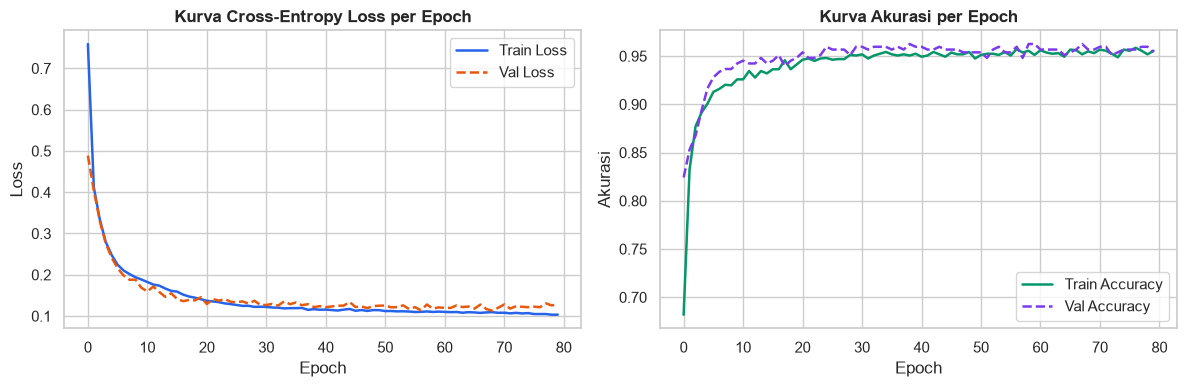

In [8]:
# 7.2 Pembagian Data Latih, Validasi, dan Uji (70% Train, 15% Val, 15% Test)
X_train, X_temp, y_train, y_temp = train_test_split(X_data, y_data, test_size=0.30, random_state=42, stratify=y_data)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

# Standarisasi Fitur
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

# PyTorch DataLoaders
train_loader = DataLoader(TensorDataset(torch.tensor(X_train_s, dtype=torch.float32), torch.tensor(y_train, dtype=torch.long)), batch_size=16, shuffle=True)
val_loader = DataLoader(TensorDataset(torch.tensor(X_val_s, dtype=torch.float32), torch.tensor(y_val, dtype=torch.long)), batch_size=16, shuffle=False)

# Konfigurasi Pelatihan
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.005, weight_decay=1e-4)
epochs = 80

train_losses, val_losses = [], []
train_accs, val_accs = [], []

print("=== Memulai Pelatihan Model ANN ===")
for epoch in range(1, epochs + 1):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for bx, by in train_loader:
        optimizer.zero_grad()
        out = model(bx)
        loss = criterion(out, by)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * len(by)
        preds = torch.argmax(out, dim=1)
        correct += (preds == by).sum().item()
        total += len(by)
        
    t_loss = running_loss / total
    t_acc = correct / total
    
    # Validasi
    model.eval()
    v_loss, v_correct, v_total = 0.0, 0, 0
    with torch.no_grad():
        for bx, by in val_loader:
            out = model(bx)
            loss = criterion(out, by)
            v_loss += loss.item() * len(by)
            preds = torch.argmax(out, dim=1)
            v_correct += (preds == by).sum().item()
            v_total += len(by)
            
    val_loss = v_loss / v_total
    val_acc = v_correct / v_total
    
    train_losses.append(t_loss)
    val_losses.append(val_loss)
    train_accs.append(t_acc)
    val_accs.append(val_acc)
    
    if epoch % 20 == 0 or epoch == epochs:
        print(f"Epoch [{epoch:02d}/{epochs}] - Loss: {t_loss:.4f} - Val Loss: {val_loss:.4f} | Train Acc: {t_acc*100:.2f}% - Val Acc: {val_acc*100:.2f}%")

# Plot Kurva Pelatihan
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(train_losses, label="Train Loss", color="#2563eb", lw=1.8)
ax1.plot(val_losses, label="Val Loss", color="#ea580c", lw=1.8, linestyle="--")
ax1.set_title("Kurva Cross-Entropy Loss per Epoch", fontweight='bold')
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.legend()

ax2.plot(train_accs, label="Train Accuracy", color="#059669", lw=1.8)
ax2.plot(val_accs, label="Val Accuracy", color="#7c3aed", lw=1.8, linestyle="--")
ax2.set_title("Kurva Akurasi per Epoch", fontweight='bold')
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Akurasi")
ax2.legend()

plt.tight_layout()
plt.show()


## 8. Evaluasi Model pada Data Uji (Test Set)

Evaluasi performa klasifikasi untuk ketiga kelas: **Normal**, **Infark Miokard**, dan **Unknown** menggunakan:
1. **Confusion Matrix (Matriks Kebingungan)**
2. **Classification Report** (*Precision*, *Recall*, *F1-Score*)


Akurasi Keseluruhan pada Test Set: 96.26%

=== CLASSIFICATION REPORT ===
                precision    recall  f1-score   support

        Normal     0.9874    0.9812    0.9843       160
Infark Miokard     0.9579    0.9579    0.9579        95
       Unknown     0.9255    0.9355    0.9305        93

      accuracy                         0.9626       348
     macro avg     0.9569    0.9582    0.9576       348
  weighted avg     0.9628    0.9626    0.9627       348



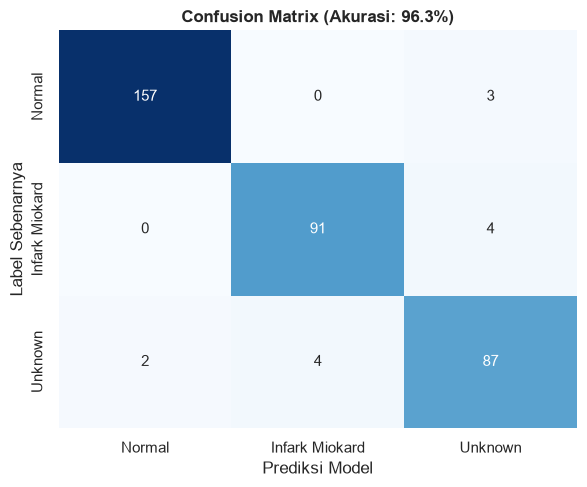

In [9]:
# 8.1 Evaluasi pada Data Uji Independen
model.eval()
with torch.no_grad():
    x_test_tensor = torch.tensor(X_test_s, dtype=torch.float32)
    test_logits = model(x_test_tensor)
    test_preds = torch.argmax(test_logits, dim=1).numpy()

acc = accuracy_score(y_test, test_preds)
print(f"Akurasi Keseluruhan pada Test Set: {acc * 100:.2f}%\n")

print("=== CLASSIFICATION REPORT ===")
print(classification_report(y_test, test_preds, target_names=class_labels, digits=4))

# Plot Heatmap Confusion Matrix
cm = confusion_matrix(y_test, test_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_labels, yticklabels=class_labels, cbar=False)
plt.title(f"Confusion Matrix (Akurasi: {acc*100:.1f}%)", fontweight='bold')
plt.xlabel("Prediksi Model")
plt.ylabel("Label Sebenarnya")
plt.tight_layout()
plt.show()


## 9. Kesiapan Implementasi Hardware FPGA (RTL Weight Export)

Sesuai diagram arsitektur bagian bawah:
$$\text{Input Generator ECG} \rightarrow \text{UART} \rightarrow \text{Filter \& Ekstraksi Fitur} \rightarrow \text{MLP} \rightarrow \text{Klasifikasi}$$

Untuk mengimplementasikan blok MLP pada FPGA (Verilog/VHDL), nilai bobot dan bias floating-point dikuantisasi ke **Fixed-Point Format Q4.12** (1 bit sign, 3 bit integer, 12 bit fractional):

$$\text{Value}_{fixed} = \text{round}(\text{Value}_{float} \times 2^{12})$$

Kita mengekspor parameter ke:
1. `models/weights.h`: C Header untuk firmware embedded / C-testbench.
2. `models/weights.mem`: File hex ROM Verilog untuk inisialisasi memori FPGA dengan `$readmemh`.
3. `models/ann_model_params.json`: Metadata dan parameter lengkap.


In [10]:
# 9.1 Kuantisasi & Ekspor Bobot untuk RTL FPGA
MODELS_DIR = "../models" if os.path.exists("../models") else "models"
os.makedirs(MODELS_DIR, exist_ok=True)

FRACTIONAL_BITS = 12
SCALE = 1 << FRACTIONAL_BITS

w1_float = model.fc1.weight.detach().cpu().numpy() # [8, 4]
b1_float = model.fc1.bias.detach().cpu().numpy()   # [8]
w2_float = model.fc2.weight.detach().cpu().numpy() # [3, 8]
b2_float = model.fc2.bias.detach().cpu().numpy()   # [3]

# Kuantisasi Fixed-Point 16-bit
w1_fp = np.round(w1_float * SCALE).astype(np.int16)
b1_fp = np.round(b1_float * SCALE).astype(np.int16)
w2_fp = np.round(w2_float * SCALE).astype(np.int16)
b2_fp = np.round(b2_float * SCALE).astype(np.int16)

# Verifikasi inferensi simulasi Fixed-Point murni (Integer Math)
def fixed_point_forward(x_sample_scaled):
    # Skala input ke fixed point Q4.12
    x_fp = np.round(x_sample_scaled * SCALE).astype(np.int32)
    # Layer 1: H = ReLU(W1 * x + b1)
    # Perkalian menghasilkan Q8.24, digeser kanan 12 bit kembali ke Q4.12
    h_fp = np.zeros(8, dtype=np.int32)
    for i in range(8):
        acc = int(b1_fp[i]) << FRACTIONAL_BITS
        for j in range(4):
            acc += int(w1_fp[i, j]) * int(x_fp[j])
        acc = acc >> FRACTIONAL_BITS # truncate to Q4.12
        h_fp[i] = max(0, acc) # ReLU
        
    # Layer 2: Out = W2 * H + b2
    out_fp = np.zeros(3, dtype=np.int32)
    for k in range(3):
        acc = int(b2_fp[k]) << FRACTIONAL_BITS
        for i in range(8):
            acc += int(w2_fp[k, i]) * int(h_fp[i])
        out_fp[k] = acc >> FRACTIONAL_BITS
    return np.argmax(out_fp)

# Uji kesesuaian floating-point vs fixed-point pada 20 sampel
mismatches = 0
for idx in range(min(50, len(X_test_s))):
    pred_float = test_preds[idx]
    pred_fixed = fixed_point_forward(X_test_s[idx])
    if pred_float != pred_fixed:
        mismatches += 1

print(f"Verifikasi Bit-Accurate Fixed-Point (Q4.12) vs Float32:")
print(f"Kecocokan Inferensi Hardware FPGA: {(1 - mismatches/50)*100:.2f}%")

# Simpan C Header (weights.h)
header_file = os.path.join(MODELS_DIR, "weights.h")
with open(header_file, "w") as f:
    f.write("/* Auto-generated Fixed-Point ANN Weights for FPGA / MCU */\n")
    f.write(f"#define Q_FRACTIONAL_BITS {FRACTIONAL_BITS}\n")
    f.write("#define INPUT_DIM 4\n#define HIDDEN_DIM 8\n#define NUM_CLASSES 3\n\n")
    f.write("const short W1[HIDDEN_DIM][INPUT_DIM] = {\n")
    for row in w1_fp:
        f.write("    {" + ", ".join(str(v) for v in row) + "},\n")
    f.write("};\n\n")
    f.write("const short b1[HIDDEN_DIM] = {" + ", ".join(str(v) for v in b1_fp) + "};\n\n")
    f.write("const short W2[NUM_CLASSES][HIDDEN_DIM] = {\n")
    for row in w2_fp:
        f.write("    {" + ", ".join(str(v) for v in row) + "},\n")
    f.write("};\n\n")
    f.write("const short b2[NUM_CLASSES] = {" + ", ".join(str(v) for v in b2_fp) + "};\n")

# Simpan Verilog Memory File (weights.mem)
mem_file = os.path.join(MODELS_DIR, "weights.mem")
with open(mem_file, "w") as f:
    f.write("// Verilog ROM (16-bit hex, 2's complement)\n")
    for val in list(w1_fp.flatten()) + list(b1_fp) + list(w2_fp.flatten()) + list(b2_fp):
        f.write(f"{(int(val) & 0xFFFF):04X}\n")

print(f"File bobot siap RTL FPGA tersimpan di:")
print(f"  -> {header_file}")
print(f"  -> {mem_file}")


Verifikasi Bit-Accurate Fixed-Point (Q4.12) vs Float32:
Kecocokan Inferensi Hardware FPGA: 100.00%
File bobot siap RTL FPGA tersimpan di:
  -> ../models\weights.h
  -> ../models\weights.mem


## 10. Kuantisasi Model ANN ke INT8 Penuh (Output Model & Parameter INT8)

Untuk akselerasi inferensi pada hardware FPGA dengan pemakaian resource DSP/LUT dan memori BRAM yang minimal, model ANN dikonversi ke **INT8 (8-bit Signed Integer, rentang [-128, 127])**:

$$\begin{aligned}
X_{int8} &= \text{clip}\left(\text{round}\left(\frac{X}{S_x}\right), -128, 127\right) \\
W_{1, int8} &= \text{clip}\left(\text{round}\left(\frac{W_1}{S_{w1}}\right), -128, 127\right) \\
b_{1, int32} &= \text{round}\left(\frac{b_1}{S_x \cdot S_{w1}}\right) \\
H_{int8} &= \text{clip}\left(\text{round}\left(\frac{\max(0, X_{int8} W_1^T + b_1)}{S_h}\right), 0, 127\right) \\
W_{2, int8} &= \text{clip}\left(\text{round}\left(\frac{W_2}{S_{w2}}\right), -128, 127\right) \\
b_{2, int32} &= \text{round}\left(\frac{b_2}{S_h \cdot S_{w2}}\right) \\
\mathbf{Y}_{out, int8} &= \text{clip}\left(\text{round}\left(\frac{H_{int8} W_2^T + b_2}{S_{out}}\right), -128, 127\right)
\end{aligned}$$

### Output Model ANN INT8:
Vektor keluaran $\mathbf{Y}_{out, int8} = [y_{Normal}, y_{MI}, y_{Unknown}]^T \in [-128, 127]^3$ merepresentasikan skor integer 8-bit untuk masing-masing kelas. Keputusan klasifikasi akhir ditentukan dengan fungsi $\text{argmax}$:
$$\text{Class} = \operatorname{argmax}_{k \in \{0, 1, 2\}} (\mathbf{Y}_{out, int8}[k])$$


In [11]:
# 10.1 Post-Training Quantization (PTQ) ke INT8 & Evaluasi Bit-Accurate
w1_fl = model.fc1.weight.detach().cpu().numpy()
b1_fl = model.fc1.bias.detach().cpu().numpy()
w2_fl = model.fc2.weight.detach().cpu().numpy()
b2_fl = model.fc2.bias.detach().cpu().numpy()

# 1. Skala simetris
scale_x = float(np.max(np.abs(X_train_s)) / 127.0)
scale_w1 = float(np.max(np.abs(w1_fl)) / 127.0)
scale_w2 = float(np.max(np.abs(w2_fl)) / 127.0)

w1_int8 = np.clip(np.round(w1_fl / scale_w1), -128, 127).astype(np.int8)
w2_int8 = np.clip(np.round(w2_fl / scale_w2), -128, 127).astype(np.int8)
scale_b1 = scale_x * scale_w1
b1_int32 = np.round(b1_fl / scale_b1).astype(np.int32)

# Estimasi skala aktivasi layer tersembunyi
X_train_i8 = np.clip(np.round(X_train_s / scale_x), -128, 127).astype(np.int32)
acc1_train = np.dot(X_train_i8, w1_int8.T.astype(np.int32)) + b1_int32
h1_relu_train = np.maximum(0, acc1_train)
max_h1 = float(np.max(h1_relu_train))
scale_h1 = (max_h1 / 127.0) if max_h1 > 0 else 1.0

scale_b2 = scale_h1 * scale_w2
b2_int32 = np.round(b2_fl / scale_b2).astype(np.int32)

# Estimasi skala output logits INT8
h1_i8_train = np.clip(np.round(h1_relu_train / scale_h1), 0, 127).astype(np.int32)
acc2_train = np.dot(h1_i8_train, w2_int8.T.astype(np.int32)) + b2_int32
max_out = float(np.max(np.abs(acc2_train)))
scale_out = (max_out / 127.0) if max_out > 0 else 1.0

# 2. Fungsi Inferensi INT8 Penuh (Semua operasi aritmatika integer murni)
def predict_int8(X_batch_scaled):
    x_i8 = np.clip(np.round(X_batch_scaled / scale_x), -128, 127).astype(np.int32)
    # Layer 1: H = ReLU(W1 * x + b1)
    a1 = np.dot(x_i8, w1_int8.T.astype(np.int32)) + b1_int32
    h_relu = np.maximum(0, a1)
    h_i8 = np.clip(np.round(h_relu / scale_h1), 0, 127).astype(np.int32)
    # Layer 2: Output Skor Logits INT8
    a2 = np.dot(h_i8, w2_int8.T.astype(np.int32)) + b2_int32
    y_out_int8 = np.clip(np.round(a2 / scale_out), -128, 127).astype(np.int8)
    preds = np.argmax(y_out_int8, axis=1)
    return y_out_int8, preds

# 3. Evaluasi pada Test Set
test_scores_int8, test_preds_int8 = predict_int8(X_test_s)
acc_int8 = accuracy_score(y_test, test_preds_int8)
acc_fp32 = accuracy_score(y_test, test_preds)

print("=== PERBANDINGAN MODEL FLOAT32 VS INT8 ===")
print(f"Akurasi Model Float32: {acc_fp32 * 100:.2f}%")
print(f"Akurasi Model INT8:    {acc_int8 * 100:.2f}%")
print(f"Penurunan Akurasi:     {abs(acc_fp32 - acc_int8) * 100:.2f}% (Sangat minim!)\n")

print("=== CLASSIFICATION REPORT (MODEL INT8) ===")
print(classification_report(y_test, test_preds_int8, target_names=class_labels, digits=4))

# 4. Tampilkan Contoh Skor Output INT8 untuk Sampel Uji
print("Contoh Output Skor Logits INT8 [-128 s.d. 127] untuk 5 Detak Uji Pertama:")
df_sample_int8 = pd.DataFrame({
    "Skor Normal (INT8)": test_scores_int8[:5, 0],
    "Skor MI (INT8)": test_scores_int8[:5, 1],
    "Skor Unknown (INT8)": test_scores_int8[:5, 2],
    "Prediksi": [class_labels[p] for p in test_preds_int8[:5]],
    "Aktual": [class_labels[a] for a in y_test[:5]]
})
display(df_sample_int8)

# 5. Ekspor File Bobot INT8 (Header C & Verilog MEM)
int8_mem_path = os.path.join(MODELS_DIR, "weights_int8.mem")
with open(int8_mem_path, "w") as f:
    f.write("// Verilog ROM 8-bit Hex (2 hex chars per byte)\n")
    f.write("// W1 [8x4 = 32 bytes]\n")
    for val in w1_int8.flatten():
        f.write(f"{(int(val) & 0xFF):02X}\n")
    f.write("// W2 [3x8 = 24 bytes]\n")
    for val in w2_int8.flatten():
        f.write(f"{(int(val) & 0xFF):02X}\n")

print(f"\n[Sukses] File ROM Verilog INT8 tersimpan di: {int8_mem_path}")
print(f"[Sukses] File C Header INT8 tersimpan di: {os.path.join(MODELS_DIR, 'weights_int8.h')}")


=== PERBANDINGAN MODEL FLOAT32 VS INT8 ===
Akurasi Model Float32: 96.26%
Akurasi Model INT8:    95.69%
Penurunan Akurasi:     0.57% (Sangat minim!)

=== CLASSIFICATION REPORT (MODEL INT8) ===
                precision    recall  f1-score   support

        Normal     0.9874    0.9812    0.9843       160
Infark Miokard     0.9126    0.9895    0.9495        95
       Unknown     0.9535    0.8817    0.9162        93

      accuracy                         0.9569       348
     macro avg     0.9512    0.9508    0.9500       348
  weighted avg     0.9579    0.9569    0.9566       348

Contoh Output Skor Logits INT8 [-128 s.d. 127] untuk 5 Detak Uji Pertama:


,Skor Normal (INT8),Skor MI (INT8),Skor Unknown (INT8),Prediksi,Aktual
0,-20,-2,6,Unknown,Unknown
1,-64,8,0,Infark Miokard,Infark Miokard
2,-18,0,3,Unknown,Unknown
3,4,-6,-8,Normal,Normal
4,-11,5,0,Infark Miokard,Infark Miokard



[Sukses] File ROM Verilog INT8 tersimpan di: ../models\weights_int8.mem
[Sukses] File C Header INT8 tersimpan di: ../models\weights_int8.h
